# 09 – Đánh giá cuối cùng trên tập test, độ quan trọng đặc trưng (RQ3) và lưu mô hình

Các notebook 04–08 chỉ dùng train (CV) và validation để chọn mô hình. Notebook này:

1. Chốt **hai thiết lập** và mô hình đại diện cho mỗi thiết lập (đã chọn ở notebook 07, 08):
   - **A – Không có lịch sử điện** (bộ `full`: cảm biến + thời tiết + `lights` + thời gian): đúng bài toán của bài báo gốc.
   - **B – Có lịch sử điện** (bộ `lag_time`: thời gian + tiêu thụ 10–60 phút trước): dự báo 10 phút tới.
2. Huấn luyện lại trên **train + validation**, đánh giá **một lần duy nhất** trên **test** (3 tuần cuối) → RQ1.
3. **RQ3:** độ quan trọng đặc trưng bằng *permutation importance*, so với biến ngẫu nhiên `rv1`.
4. Lưu mô hình cuối cùng vào `models/best_model.joblib` cho demo `app/`.

In [1]:
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso

from src.config import MODELS_DIR, RANDOM_STATE, TABLES_DIR, TARGET
from src.data_loader import load_raw_data
from src.evaluate import HourMeanBaseline, regression_metrics
from src.features import add_lag_features, add_time_features, get_feature_columns, make_xy
from src.preprocessing import make_pipeline
from src.split import describe_split, time_split
from src.visualization import save_fig, set_style

warnings.filterwarnings("ignore", category=ConvergenceWarning)
set_style()
pd.set_option("display.width", 160)

data = add_lag_features(add_time_features(load_raw_data()))
train, val, test = time_split(data)
train_val = pd.concat([train, val])
best_hgb = json.loads((TABLES_DIR / "07_best_hgb_params.json").read_text())
describe_split(train, val, test)

,số mẫu,từ,đến,TB mục tiêu,trung vị
tập,,,,,
train,13814,2016-01-11 17:00:00,2016-04-16 15:10:00,98.8,60.0
validation,2960,2016-04-16 15:20:00,2016-05-07 04:30:00,93.4,60.0
test,2961,2016-05-07 04:40:00,2016-05-27 18:00:00,96.9,60.0


## 1. Mô hình của hai thiết lập

In [2]:
class Persistence(HourMeanBaseline):
    """Dự đoán = tiêu thụ 10 phút trước (cột lag_10m). Không học gì."""

    def fit(self, X, y):
        return self

    def predict(self, X):
        return np.asarray(X["lag_10m"], dtype=float)


def hgb(cols):
    return make_pipeline(HistGradientBoostingRegressor(max_iter=300, l2_regularization=1.0, early_stopping=False,
                                                       random_state=RANDOM_STATE, **best_hgb), cols, "tree")


def rf(cols):
    return make_pipeline(RandomForestRegressor(n_estimators=100, min_samples_leaf=50, max_features=0.33,
                                               random_state=RANDOM_STATE, n_jobs=-1), cols, "tree")


def lasso(cols):
    return make_pipeline(Lasso(alpha=1.0, max_iter=10000), cols, "linear")


SETTINGS = {
    "A – không lịch sử điện": dict(cols=get_feature_columns("full"), models={
        "Baseline theo giờ": lambda c: HourMeanBaseline(), "Lasso": lasso, "Random Forest": rf, "HGB": hgb}),
    "B – có lịch sử điện": dict(cols=get_feature_columns("lag_time", include_control=False), models={
        "Persistence": lambda c: Persistence(), "Lasso": lasso, "Random Forest": rf, "HGB": hgb}),
}
for name, s in SETTINGS.items():
    print(f"{name}: {len(s['cols'])} đặc trưng")

A – không lịch sử điện: 31 đặc trưng
B – có lịch sử điện: 12 đặc trưng


## 2. Đánh giá trên tập test (RQ1)

Huấn luyện lại trên train + validation (16 774 mẫu, 11/01 – 07/05/2016), dự đoán test (2 961 mẫu, 07/05 – 27/05/2016).

In [3]:
test_rows, fitted, preds = {}, {}, {}
for setting, s in SETTINGS.items():
    cols = s["cols"]
    lag_cols = [c for c in cols if c.startswith(("lag_", "roll_", "diff_"))]
    tv = train_val.dropna(subset=lag_cols) if lag_cols else train_val
    X_tv, y_tv = tv[cols], tv[TARGET]
    X_te, y_te = test[cols], test[TARGET]
    for name, make in s["models"].items():
        model = make(cols).fit(X_tv, y_tv)
        p = model.predict(X_te)
        fitted[(setting, name)] = model
        preds[(setting, name)] = p
        test_rows[(setting, name)] = regression_metrics(y_te, p)
test_results = pd.DataFrame(test_rows).T.round(3)
test_results.index.names = ["thiết lập", "mô hình"]
test_results.to_csv(TABLES_DIR / "09_test_results.csv")
test_results

MAE    RMSE     R2  MAPE_%
thiết lập              mô hình                                         
A – không lịch sử điện Baseline theo giờ  46.490  84.880  0.128  46.347
                       Lasso              48.985  84.169  0.142  53.162
                       Random Forest      72.112  98.252 -0.169  93.583
                       HGB                73.608  99.931 -0.209  95.755
B – có lịch sử điện    Persistence        26.738  66.837  0.459  21.513
                       Lasso              26.795  60.576  0.556  24.373
                       Random Forest      25.589  58.907  0.580  22.521
                       HGB                25.248  58.888  0.580  22.025

Đã lưu hình: reports/figures/09_test_results.png


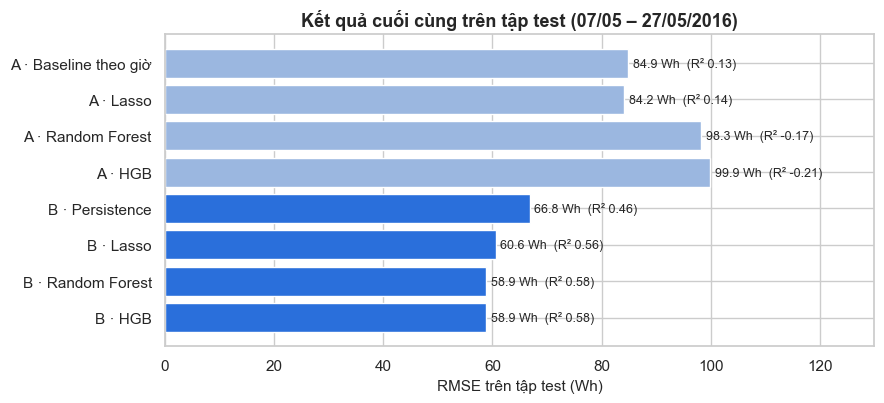

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
labels = [f"{s.split(' – ')[0]} · {m}" for s, m in test_results.index]
colors = ["#9bb7e0" if s.startswith("A") else "#2a6fdb" for s, _ in test_results.index]
y = np.arange(len(test_results))[::-1]
ax.barh(y, test_results["RMSE"], color=colors)
for yi, v, r2 in zip(y, test_results["RMSE"], test_results["R2"]):
    ax.text(v + 0.8, yi, f"{v:.1f} Wh  (R² {r2:.2f})", va="center", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("RMSE trên tập test (Wh)")
ax.set_xlim(0, max(test_results["RMSE"]) * 1.3)
ax.set_title("Kết quả cuối cùng trên tập test (07/05 – 27/05/2016)")
fig.tight_layout()
save_fig(fig, "09_test_results")
plt.show()

**Nhận xét (RQ1):**
- **Thiết lập B (có lịch sử điện):** HGB và Random Forest cùng đạt RMSE ≈ **58,9 Wh**, R² **0,58**, tốt hơn persistence (66,8 Wh) **11,9%** và tốt hơn baseline theo giờ **30,6%**. Kết quả test gần với validation (57,4 Wh): mô hình **tổng quát hóa tốt** sang giai đoạn mới.
- **Thiết lập A (chỉ môi trường):** Lasso (84,2 Wh) chỉ hơn baseline theo giờ (84,9 Wh) **0,8%**. Random Forest và HGB – tốt nhất trên validation – lại **sụp đổ** trên test (RMSE ≈ 98–100 Wh, R² **âm**), kém cả baseline. Mục 2.1 phân tích nguyên nhân.
- **Trả lời RQ1:** chỉ với cảm biến môi trường + thời tiết + thời gian, dự đoán **gần như không hơn** việc biết giờ trong ngày. Khi có tiêu thụ 10–60 phút trước, mô hình giải thích được ~58% phương sai và vượt rõ các baseline.

### 2.1 Vì sao mô hình cây của thiết lập A thất bại trên test?
So sánh mức dự đoán trung bình với thực tế, và nhiệt độ của giai đoạn test với giai đoạn huấn luyện.

In [5]:
setting_A = "A – không lịch sử điện"
bias = pd.DataFrame({
    "dự đoán TB (Wh)": {m: preds[(setting_A, m)].mean() for m in SETTINGS[setting_A]["models"]},
}).assign(**{"thực tế TB (Wh)": test[TARGET].mean()})
bias["lệch (Wh)"] = bias["dự đoán TB (Wh)"] - bias["thực tế TB (Wh)"]
print(bias.round(1).to_string())
print()
shift = pd.DataFrame({
    "TB train+val": train_val[["T3", "T2", "T6", "T9", "T_out"]].mean(),
    "TB test": test[["T3", "T2", "T6", "T9", "T_out"]].mean(),
    "% test vượt max train+val": 100 * (test[["T3", "T2", "T6", "T9", "T_out"]]
                                         > train_val[["T3", "T2", "T6", "T9", "T_out"]].max()).mean(),
})
shift.round(1)

                   dự đoán TB (Wh)  thực tế TB (Wh)  lệch (Wh)
Baseline theo giờ             98.1             96.9        1.2
Lasso                        103.9             96.9        7.0
Random Forest                141.8             96.9       44.9
HGB                          143.0             96.9       46.1



,TB train+val,TB test,% test vượt max train+val
T3,21.7,25.5,3.9
T2,19.8,23.6,5.6
T6,6.5,16.0,8.8
T9,18.9,23.1,18.2
T_out,6.2,14.5,5.2


**Nhận xét – trôi dạt theo mùa (distribution shift):**
- Random Forest và HGB dự đoán **cao hơn thực tế ~45 Wh** trên toàn bộ test; Lasso chỉ lệch 7 Wh, baseline theo giờ 1 Wh.
- Tập test (07–27/05) **ấm hơn hẳn** giai đoạn huấn luyện: nhiệt độ phòng giặt `T3` trung bình 21,7 → 25,5 °C, ngoài trời `T_out` 6,2 → 14,5 °C.
- Một giải thích khả dĩ: trong mùa lạnh, `T3` cao thường đi kèm lúc **máy giặt/máy sấy đang chạy** (thiết bị làm nóng phòng) → mô hình cây học quy tắc "`T3` cao ⇒ tiêu thụ cao" (`T3` là đặc trưng quan trọng thứ 2 ở mục 3). Sang tháng 5, `T3` cao vì **thời tiết** nên quy tắc này cho kết quả sai. Chỉ ~4% giá trị `T3` của test vượt khoảng huấn luyện, nên vấn đề chính là **quan hệ không ổn định theo mùa**, không phải ngoại suy.
- Lasso bị ảnh hưởng ít hơn vì điều chuẩn giữ hệ số nhỏ. Mô hình cây linh hoạt hơn nên "học thuộc" mạnh hơn các quan hệ chỉ đúng trong mùa đông.
- **Bài học:** quan hệ giữa cảm biến môi trường và điện năng **không ổn định theo mùa**. Validation (16/04–07/05) chưa đủ khác biệt để phát hiện điều này. Muốn dùng thiết lập A cần dữ liệu đủ một năm, hoặc đặc trưng ít phụ thuộc mùa hơn (ví dụ chênh lệch `T3 − T_out`). Đây là hướng phát triển.

### 2.2 Dự đoán theo thời gian – 2 ngày đầu tập test

Đã lưu hình: reports/figures/09_test_timeseries.png


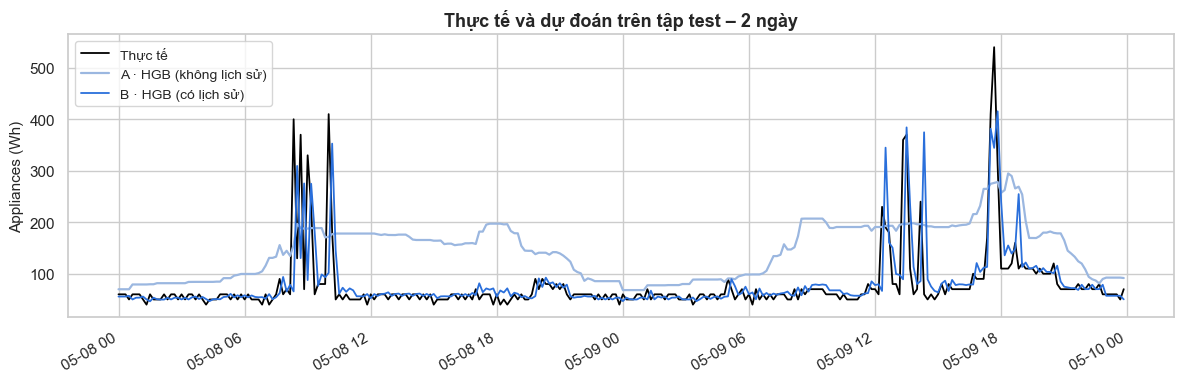

In [6]:
start = test["date"].iloc[0].normalize() + pd.Timedelta(days=1)
mask = (test["date"] >= start) & (test["date"] < start + pd.Timedelta(days=2))
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test["date"][mask], test[TARGET][mask], color="black", linewidth=1.3, label="Thực tế")
ax.plot(test["date"][mask], preds[("A – không lịch sử điện", "HGB")][mask.to_numpy()],
        color="#9bb7e0", linewidth=1.6, label="A · HGB (không lịch sử)")
ax.plot(test["date"][mask], preds[("B – có lịch sử điện", "HGB")][mask.to_numpy()],
        color="#2a6fdb", linewidth=1.3, label="B · HGB (có lịch sử)")
ax.set_ylabel("Appliances (Wh)")
ax.set_title("Thực tế và dự đoán trên tập test – 2 ngày")
ax.legend(loc="upper left")
fig.autofmt_xdate()
fig.tight_layout()
save_fig(fig, "09_test_timeseries")
plt.show()

In [7]:
bins = [0, 60, 100, 200, 2000]
level_labels = ["≤ 60 Wh", "60–100 Wh", "100–200 Wh", "> 200 Wh"]
group = pd.cut(test[TARGET], bins=bins, labels=level_labels)
err = pd.DataFrame({
    "A · HGB": np.abs(preds[("A – không lịch sử điện", "HGB")] - test[TARGET]),
    "B · Persistence": np.abs(preds[("B – có lịch sử điện", "Persistence")] - test[TARGET]),
    "B · HGB": np.abs(preds[("B – có lịch sử điện", "HGB")] - test[TARGET]),
})
by_level = err.groupby(group, observed=False).mean().round(1)
by_level["số mẫu"] = group.value_counts().reindex(level_labels)
by_level

,A · HGB,B · Persistence,B · HGB,số mẫu
Appliances,,,,
≤ 60 Wh,61.1,8.8,9.3,1503
60–100 Wh,78.1,18.2,20.4,829
100–200 Wh,58.5,37.0,35.1,381
> 200 Wh,157.5,148.0,122.9,248


**Nhận xét:**
- **B · HGB** có lợi nhất ở các **đỉnh > 200 Wh**: sai số 122,9 Wh so với 148,0 Wh của persistence. Mô hình học được khi nào đỉnh sắp kết thúc thay vì lặp lại giá trị cũ.
- Ở mức nền (≤ 100 Wh), HGB kém persistence một chút (9,3 so với 8,8 Wh và 20,4 so với 18,2 Wh) vì dự đoán được làm mượt. Persistence đúng tuyệt đối khi tiêu thụ đứng yên.
- **A · HGB** sai lớn ở **mọi** mức (61 Wh ngay cả khi tiêu thụ ≤ 60 Wh). Đây là hệ quả của độ lệch hệ thống ở mục 2.1 (hình trên: đường A nằm cao hơn thực tế suốt ban ngày).

## 3. Độ quan trọng đặc trưng (RQ3)

**Permutation importance:** xáo trộn ngẫu nhiên một cột rồi đo RMSE tăng bao nhiêu. Đặc trưng càng quan trọng, xáo
trộn nó càng làm mô hình tệ đi. Ưu điểm so với MDI (notebook 05): đo trên dữ liệu **chưa thấy** và không thiên vị biến
có nhiều giá trị khác nhau.

- Tính trên **validation**, mô hình huấn luyện trên **train** – tập test không dùng để phân tích.
- Giữ `rv1` (biến ngẫu nhiên thuần túy) trong cả hai mô hình làm **ngưỡng đối chứng**, theo đúng ý tưởng của bài báo gốc:
  đặc trưng nào có độ quan trọng ≤ `rv1` được xem là không mang thông tin.

In [8]:
def perm_importance(feature_set):
    X_tr, y_tr = make_xy(train, feature_set)
    X_va, y_va = make_xy(val, feature_set)
    model = hgb(list(X_tr.columns)).fit(X_tr, y_tr)
    r = permutation_importance(model, X_va, y_va, scoring="neg_root_mean_squared_error",
                               n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    return pd.DataFrame({"tăng RMSE (Wh)": r.importances_mean, "std": r.importances_std},
                        index=X_va.columns).sort_values("tăng RMSE (Wh)", ascending=False)


imp_A = perm_importance("full")
imp_B = perm_importance("full_lag")
for name, imp in (("A (full)", imp_A), ("B (full_lag)", imp_B)):
    rv = imp.loc["rv1", "tăng RMSE (Wh)"]
    below = imp.index[imp["tăng RMSE (Wh)"] <= rv].drop("rv1").tolist()
    print(f"{name}: rv1 xếp hạng {imp.index.get_loc('rv1') + 1}/{len(imp)} "
          f"(tăng RMSE {rv:.3f} Wh). Đặc trưng không hơn rv1: {len(below)}")
imp_A.head(12).round(3)

A (full): rv1 xếp hạng 22/31 (tăng RMSE 0.000 Wh). Đặc trưng không hơn rv1: 10
B (full_lag): rv1 xếp hạng 14/38 (tăng RMSE 0.001 Wh). Đặc trưng không hơn rv1: 24


,tăng RMSE (Wh),std
nsm,7.295,0.580
T3,6.477,0.726
hour_sin,1.654,0.332
T2,0.559,0.071
lights,0.513,0.239
T6,0.482,0.068
T9,0.442,0.092
T_out,0.429,0.128
RH_3,0.378,0.041
hour_cos,0.366,0.184


Đã lưu hình: reports/figures/09_permutation_importance.png


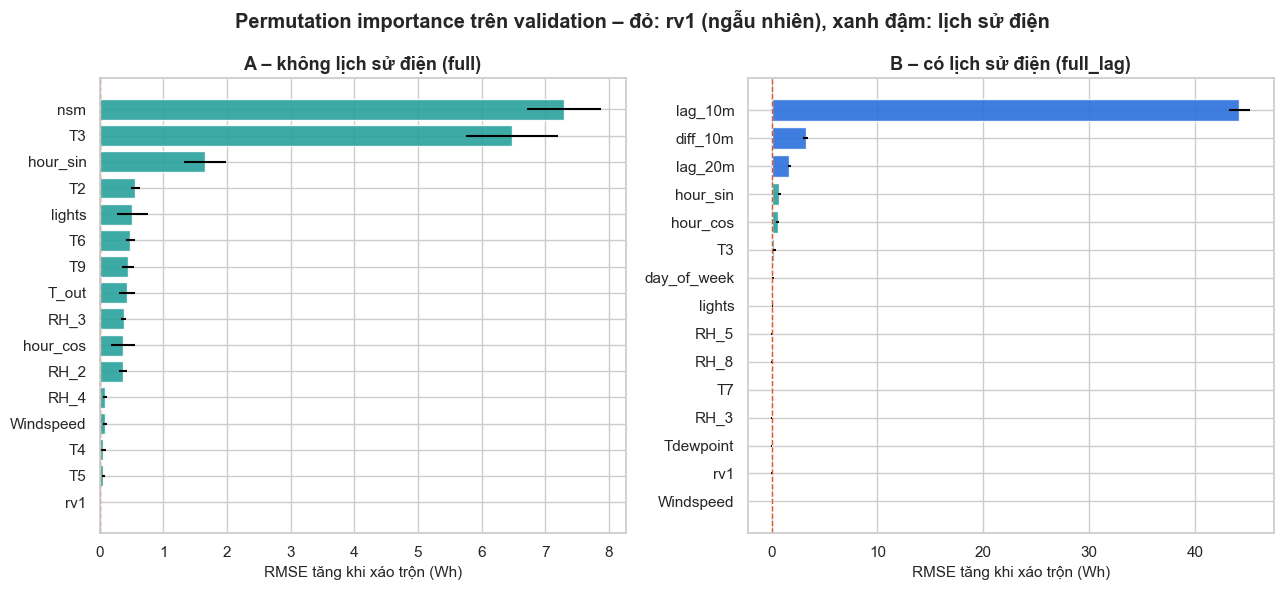

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (title, imp) in zip(axes, (("A – không lịch sử điện (full)", imp_A), ("B – có lịch sử điện (full_lag)", imp_B))):
    top = imp.head(15).iloc[::-1]
    if "rv1" not in top.index:
        top = pd.concat([imp.loc[["rv1"]], top])
    colors = ["#e4572e" if i == "rv1" else ("#2a6fdb" if i.startswith(("lag_", "roll_", "diff_")) else "#29a19c")
              for i in top.index]
    ax.barh(top.index, top["tăng RMSE (Wh)"], xerr=top["std"], color=colors, alpha=0.9)
    ax.axvline(imp.loc["rv1", "tăng RMSE (Wh)"], color="#e4572e", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("RMSE tăng khi xáo trộn (Wh)")
fig.suptitle("Permutation importance trên validation – đỏ: rv1 (ngẫu nhiên), xanh đậm: lịch sử điện", fontweight="bold")
fig.tight_layout()
save_fig(fig, "09_permutation_importance")
plt.show()

In [10]:
imp_A.round(3).to_csv(TABLES_DIR / "09_importance_A_full.csv")
imp_B.round(3).to_csv(TABLES_DIR / "09_importance_B_full_lag.csv")
rv = imp_A.loc["rv1", "tăng RMSE (Wh)"]
print("Thiết lập A – các đặc trưng KHÔNG quan trọng hơn rv1:")
print(imp_A[imp_A["tăng RMSE (Wh)"] <= rv].drop("rv1").round(3).to_string())

Thiết lập A – các đặc trưng KHÔNG quan trọng hơn rv1:
             tăng RMSE (Wh)    std
is_weekend            0.000  0.000
Visibility           -0.002  0.003
RH_6                 -0.008  0.063
RH_9                 -0.008  0.007
Tdewpoint            -0.043  0.037
day_of_week          -0.070  0.141
RH_7                 -0.089  0.035
Press_mm_hg          -0.151  0.031
RH_1                 -0.204  0.085
T8                   -0.308  0.081


### Kết luận RQ3 – Đặc trưng nào quan trọng nhất?

**Thiết lập A (chỉ môi trường):**
- Quan trọng nhất là **thời gian trong ngày** (`nsm` 7,4 Wh, `hour_sin` 1,7 Wh) và **nhiệt độ phòng giặt `T3`** (6,3 Wh). Tiếp theo, mỗi đặc trưng ~0,4–0,5 Wh: nhiệt độ/độ ẩm phòng khách (`T2`, `RH_2`), `lights`, `T6`, `RH_3`, `T9`, `T_out`.
- Khớp một phần với bài báo gốc: phòng giặt (`T3`, `RH_3`) và phòng khách (`T2`, `RH_2`) xếp cao. Khác ở chỗ bếp (`T1`, `RH_1`) gần như không đóng góp, và **áp suất `Press_mm_hg` (biến thời tiết quan trọng nhất theo bài báo) lại kém hơn `rv1`**. Một giải thích khả dĩ: áp suất thay đổi chậm, gần như duy nhất cho mỗi ngày. Nếu train/test xen kẽ thời gian, mô hình có thể dùng nó để "nhận ra ngày"; khi chia theo thời gian, lợi thế đó biến mất.
- **`rv1` xếp hạng 19/31.** Mô hình HGB (cây 7 lá) **không dùng `rv1` lần nào** (độ quan trọng đúng bằng 0). **13 đặc trưng không hơn biến ngẫu nhiên**: `is_weekend`, `day_of_week`, `RH_1`, `RH_6`, `RH_7`, `RH_8`, `RH_9`, `T7`, `T8`, `RH_out`, `Visibility`, `Tdewpoint`, `Press_mm_hg`. Có thể loại bỏ chúng mà không mất thông tin. (`rv2` đã bị loại từ đầu vì trùng hoàn toàn `rv1`.)
- **Lưu ý:** đặc trưng quan trọng **không có nghĩa là ổn định**. `T3` quan trọng thứ 2 trên validation nhưng cũng là nguyên nhân chính khiến mô hình A sai trên test (mục 2.1).

**Thiết lập B (có lịch sử điện, bộ `full_lag` đầy đủ 38 đặc trưng):**
- **`lag_10m` áp đảo** (44,4 Wh), tiếp theo là `diff_10m` (3,1), `lag_20m` (1,7), `hour_sin`/`hour_cos` (~0,6) và `T3` (0,2).
- **Mọi cảm biến khác ≈ 0 hoặc kém hơn `rv1`**, khớp với kết quả ở notebook 08: bỏ cảm biến không làm mô hình tệ đi.

## 4. Lưu mô hình cuối cùng

Lưu mô hình **B · HGB** (tốt nhất trên test, chỉ cần thời gian + lịch sử điện) đã huấn luyện trên train + validation.
Kèm file mô tả `best_model_info.json` để demo `app/` và người dùng sau biết mô hình cần đặc trưng gì.

In [11]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
final_setting = "B – có lịch sử điện"
final_model = fitted[(final_setting, "HGB")]
final_cols = SETTINGS[final_setting]["cols"]
joblib.dump(final_model, MODELS_DIR / "best_model.joblib")

info = {
    "model": "HistGradientBoostingRegressor",
    "params": best_hgb | {"max_iter": 300, "l2_regularization": 1.0},
    "feature_set": "lag_time",
    "features": final_cols,
    "target": TARGET,
    "trained_on": f"{train_val['date'].min()} → {train_val['date'].max()} (train + validation)",
    "test_period": f"{test['date'].min()} → {test['date'].max()}",
    "test_metrics": {k: round(float(v), 3) for k, v in test_results.loc[(final_setting, "HGB")].items()},
    "sklearn_version": sklearn.__version__,
    "notebook": "notebooks/09_final_evaluation.ipynb",
}
(MODELS_DIR / "best_model_info.json").write_text(json.dumps(info, ensure_ascii=False, indent=2), encoding="utf-8")

reloaded = joblib.load(MODELS_DIR / "best_model.joblib")
same = np.allclose(reloaded.predict(test[final_cols]), preds[(final_setting, "HGB")])
print("Đã lưu models/best_model.joblib và models/best_model_info.json")
print("Nạp lại và dự đoán giống hệt:", same)
print(json.dumps(info["test_metrics"], ensure_ascii=False))

Đã lưu models/best_model.joblib và models/best_model_info.json
Nạp lại và dự đoán giống hệt: True
{"MAE": 25.248, "RMSE": 58.888, "R2": 0.58, "MAPE_%": 22.025}


## 5. Tổng kết đồ án

| Câu hỏi | Trả lời ngắn (số liệu tập test) |
|---|---|
| **RQ1** – Dự đoán tốt đến đâu so với baseline? | Chỉ môi trường: Lasso 84,2 Wh, chỉ hơn baseline theo giờ 0,8% (R² 0,14). Có lịch sử điện: HGB **58,9 Wh**, R² **0,58**, hơn persistence 11,9%. |
| **RQ2** – Phi tuyến có vượt trội tuyến tính? | **Không** khi chỉ có dữ liệu môi trường: hơn ~1 Wh trên validation nhưng **sụp đổ trên test** do trôi dạt theo mùa. Khi có lịch sử điện: HGB/RF hơn Lasso ~1,7 Wh (≈ 3%). |
| **RQ3** – Đặc trưng quan trọng? | Môi trường: giờ trong ngày, `T3` (phòng giặt), phòng khách. 13/30 đặc trưng không hơn biến ngẫu nhiên `rv1`. Có lịch sử: `lag_10m` áp đảo. |
| **RQ4** – Thêm quá khứ gần? | RMSE giảm ~**30%** (validation 84,4 → 57,4 Wh). Cảm biến môi trường không còn đóng góp. |

**Mô hình triển khai:** HGB với 12 đặc trưng (thời gian + tiêu thụ 10–60 phút trước), dự báo **10 phút tới**. Lưu ở `models/best_model.joblib`, mô tả ở `models/best_model_info.json`, demo ở `app/app.py`.

**Hạn chế:**
1. Dữ liệu chỉ có ~4,5 tháng của **một** ngôi nhà, không phủ đủ các mùa: thiết lập A không tổng quát hóa sang tháng 5.
2. Chỉ dự báo một bước (10 phút); dự báo xa hơn chưa được đánh giá.
3. Các đỉnh > 200 Wh vẫn sai lớn (~120 Wh): bật/tắt thiết bị là hành vi con người, khó dự đoán trước.

**Hướng phát triển:** dữ liệu đủ một năm; đặc trưng ít phụ thuộc mùa (chênh lệch nhiệt độ trong/ngoài nhà); dự báo nhiều bước; mô hình chuỗi thời gian (LSTM) khi có nhiều dữ liệu hơn.